# Deep learning Project
## Ecommerce pipline

In [2]:
import math
import os
import random
from itertools import product

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset, DataLoader

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)


/Users/katia/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/katia/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu


---

# Part 1 : Data exploration

Dataset: Kaggle `asifxzaman/e-commerce-behavior-dataset8000-users`

In [3]:
path = kagglehub.dataset_download("asifxzaman/e-commerce-behavior-dataset8000-users")
print("Dataset path:", path)
print("Files:", os.listdir(path))
data = pd.read_csv(os.path.join(path, "ecommerce_user_behavior_8000.csv"))
print("Raw shape:", data.shape)


Dataset path: /Users/katia/.cache/kagglehub/datasets/asifxzaman/e-commerce-behavior-dataset8000-users/versions/1
Files: ['ecommerce_user_behavior_8000.csv']
Raw shape: (8000, 14)


## 1. Structure & quality

In [4]:
print("First rows:")
display(data.head(10))

print("\nRandom sample:")
display(data.sample(5, random_state=42))

print("\nColumn types:")
data.info()

print("\nUnique values per column:")
print(data.nunique())

First rows:


,user_id,age,gender,device_type,time_on_site,pages_viewed,previous_purchases,cart_items,discount_seen,ad_clicked,returning_user,avg_session_time,bounce_rate,purchase
0,1.0,56.0,Female,Desktop,12.90,8.0,13.0,1.0,1.0,NaN,0.0,6.97,28.18,1.0
1,2.0,46.0,Male,Mobile,15.63,9.0,4.0,6.0,1.0,1.0,1.0,19.17,86.73,1.0
2,3.0,32.0,Female,NaN,11.64,12.0,11.0,0.0,0.0,0.0,1.0,8.87,83.09,1.0
3,4.0,25.0,Female,Mobile,22.71,5.0,10.0,1.0,0.0,0.0,1.0,NaN,79.03,1.0
4,5.0,38.0,Female,Mobile,26.35,9.0,12.0,4.0,1.0,0.0,0.0,18.15,55.35,1.0
5,6.0,56.0,Female,Desktop,26.60,1.0,12.0,7.0,1.0,1.0,0.0,28.40,13.90,1.0
6,7.0,36.0,Male,Mobile,7.60,11.0,11.0,6.0,1.0,1.0,1.0,4.51,13.12,1.0
7,8.0,40.0,Female,Mobile,26.98,7.0,5.0,2.0,1.0,0.0,0.0,33.34,12.61,1.0
8,9.0,28.0,Female,Mobile,10.90,14.0,7.0,9.0,0.0,0.0,1.0,13.80,85.46,1.0
9,10.0,28.0,Female,Mobile,9.97,3.0,14.0,8.0,0.0,0.0,0.0,14.12,14.16,1.0



Random sample:


,user_id,age,gender,device_type,time_on_site,pages_viewed,previous_purchases,cart_items,discount_seen,ad_clicked,returning_user,avg_session_time,bounce_rate,purchase
2215,2216.0,48.0,Female,Desktop,4.27,17.0,8.0,2.0,1.0,1.0,0.0,6.35,65.73,1.0
2582,2583.0,20.0,Male,Mobile,NaN,18.0,12.0,1.0,0.0,1.0,1.0,3.98,80.74,1.0
1662,1663.0,50.0,Male,Mobile,18.60,14.0,1.0,1.0,1.0,1.0,1.0,21.60,96.71,1.0
3027,3028.0,28.0,Male,Mobile,1.98,17.0,4.0,9.0,0.0,1.0,0.0,0.99,67.84,1.0
4343,NaN,20.0,Male,Mobile,10.06,6.0,9.0,2.0,0.0,0.0,1.0,8.05,59.73,1.0



Column types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   user_id             7840 non-null   float64
 1   age                 7840 non-null   float64
 2   gender              7840 non-null   object 
 3   device_type         7840 non-null   object 
 4   time_on_site        7840 non-null   float64
 5   pages_viewed        7840 non-null   float64
 6   previous_purchases  7840 non-null   float64
 7   cart_items          7840 non-null   float64
 8   discount_seen       7840 non-null   float64
 9   ad_clicked          7840 non-null   float64
 10  returning_user      7840 non-null   float64
 11  avg_session_time    7840 non-null   float64
 12  bounce_rate         7840 non-null   float64
 13  purchase            7840 non-null   float64
dtypes: float64(12), object(2)
memory usage: 875.1+ KB

Unique values per column:
user_id     

Missing values:


,missing_count,missing_pct
user_id,160,2.0
age,160,2.0
gender,160,2.0
device_type,160,2.0
time_on_site,160,2.0
pages_viewed,160,2.0
previous_purchases,160,2.0
cart_items,160,2.0
discount_seen,160,2.0
ad_clicked,160,2.0



Rows with at least one missing value: 1981 (24.76%)


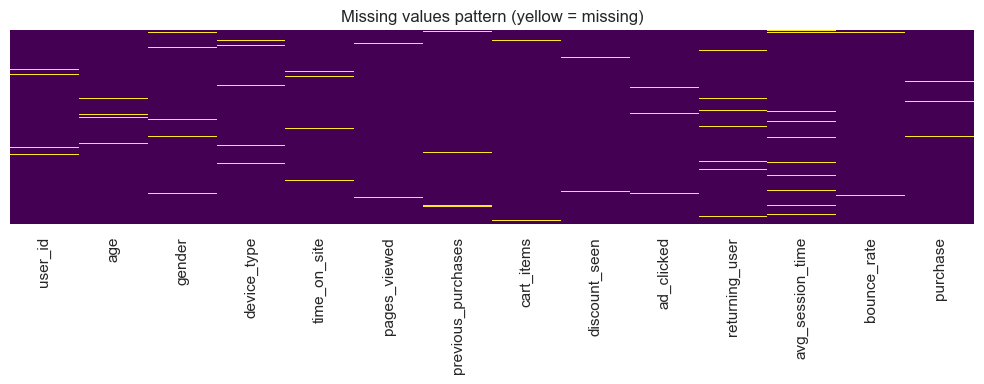

In [5]:
missing = data.isnull().sum()
missing_pct = (missing / len(data) * 100).round(2)
missing_df = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
print("Missing values:")
display(missing_df[missing_df["missing_count"] > 0])

rows_with_missing = data.isnull().any(axis=1).sum()
print(f"\nRows with at least one missing value: {rows_with_missing} ({rows_with_missing / len(data) * 100:.2f}%)")

plt.figure(figsize=(10, 4))
sns.heatmap(data.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing values pattern (yellow = missing)")
plt.tight_layout()
plt.show()

In [6]:
print(f"Duplicate rows: {data.duplicated().sum()}")
print(f"Duplicate user_id: {data['user_id'].duplicated().sum()}")

if data["user_id"].duplicated().any():
    dup_users = data[data["user_id"].duplicated(keep=False)].sort_values("user_id")
    print("\nSample duplicate user_ids:")
    display(dup_users.head(10))

Duplicate rows: 0
Duplicate user_id: 159

Sample duplicate user_ids:


,user_id,age,gender,device_type,time_on_site,pages_viewed,previous_purchases,cart_items,discount_seen,ad_clicked,returning_user,avg_session_time,bounce_rate,purchase
117,NaN,20.0,Female,Mobile,7.14,6.0,8.0,7.0,0.0,1.0,1.0,10.28,90.10,1.0
191,NaN,36.0,Female,Mobile,7.93,4.0,6.0,5.0,1.0,1.0,1.0,9.84,NaN,1.0
220,NaN,37.0,Female,Mobile,23.39,9.0,5.0,8.0,0.0,0.0,0.0,34.79,59.53,1.0
238,NaN,24.0,Male,Mobile,19.78,3.0,14.0,NaN,0.0,1.0,0.0,25.45,13.07,1.0
263,NaN,52.0,Female,Desktop,18.50,14.0,11.0,6.0,1.0,1.0,0.0,15.52,NaN,1.0
296,NaN,38.0,Female,Mobile,11.87,19.0,8.0,8.0,1.0,1.0,1.0,8.58,80.78,NaN
366,NaN,42.0,Female,Mobile,4.77,8.0,8.0,2.0,0.0,1.0,1.0,5.60,17.66,1.0
389,NaN,36.0,Male,Desktop,10.62,10.0,0.0,5.0,1.0,1.0,0.0,6.92,76.79,1.0
460,NaN,50.0,Male,Mobile,11.61,10.0,0.0,2.0,1.0,0.0,1.0,14.49,95.49,1.0
470,NaN,34.0,Male,Desktop,3.97,NaN,10.0,3.0,1.0,0.0,1.0,3.14,3.48,1.0


## 2. Target variable (`purchase`)

Purchase counts:
purchase
1.0    7827
NaN     160
0.0      13
Name: count, dtype: int64

Purchase proportions:
purchase
1.0    0.9784
NaN    0.0200
0.0    0.0016
Name: proportion, dtype: float64


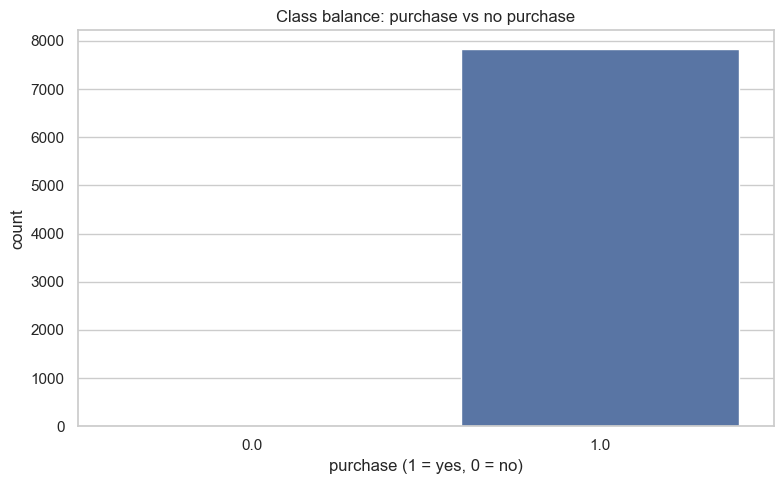

In [7]:
print("Purchase counts:")
print(data["purchase"].value_counts(dropna=False))

print("\nPurchase proportions:")
print(data["purchase"].value_counts(normalize=True, dropna=False).round(4))

plt.figure(figsize=(8, 5))
sns.countplot(x="purchase", data=data)
plt.title("Class balance: purchase vs no purchase")
plt.xlabel("purchase (1 = yes, 0 = no)")
plt.tight_layout()
plt.show()

## 3. Numerical features

In [8]:
numeric_cols = data.select_dtypes(include=["number"]).columns.tolist()
feature_cols = [c for c in numeric_cols if c not in ("user_id", "purchase")]

print("Numerical summary (excluding user_id):")
display(data[feature_cols].describe().T)

Numerical summary (excluding user_id):


,count,mean,std,min,25%,50%,75%,max
age,7840.0,38.595791,12.033928,18.00,28.0000,39.00,49.0000,59.00
time_on_site,7840.0,15.714673,8.362764,1.00,8.5200,15.74,22.8800,30.00
pages_viewed,7840.0,9.970026,5.425485,1.00,5.0000,10.00,15.0000,19.00
previous_purchases,7840.0,6.964158,4.281117,0.00,3.0000,7.00,11.0000,14.00
cart_items,7840.0,4.530230,2.865814,0.00,2.0000,5.00,7.0000,9.00
discount_seen,7840.0,0.502551,0.500025,0.00,0.0000,1.00,1.0000,1.00
ad_clicked,7840.0,0.502296,0.500027,0.00,0.0000,1.00,1.0000,1.00
returning_user,7840.0,0.509439,0.499943,0.00,0.0000,1.00,1.0000,1.00
avg_session_time,7840.0,15.794999,9.864556,0.57,7.7500,14.30,22.3925,44.75
bounce_rate,7840.0,49.924402,29.137449,0.01,24.6775,49.50,75.9900,99.97


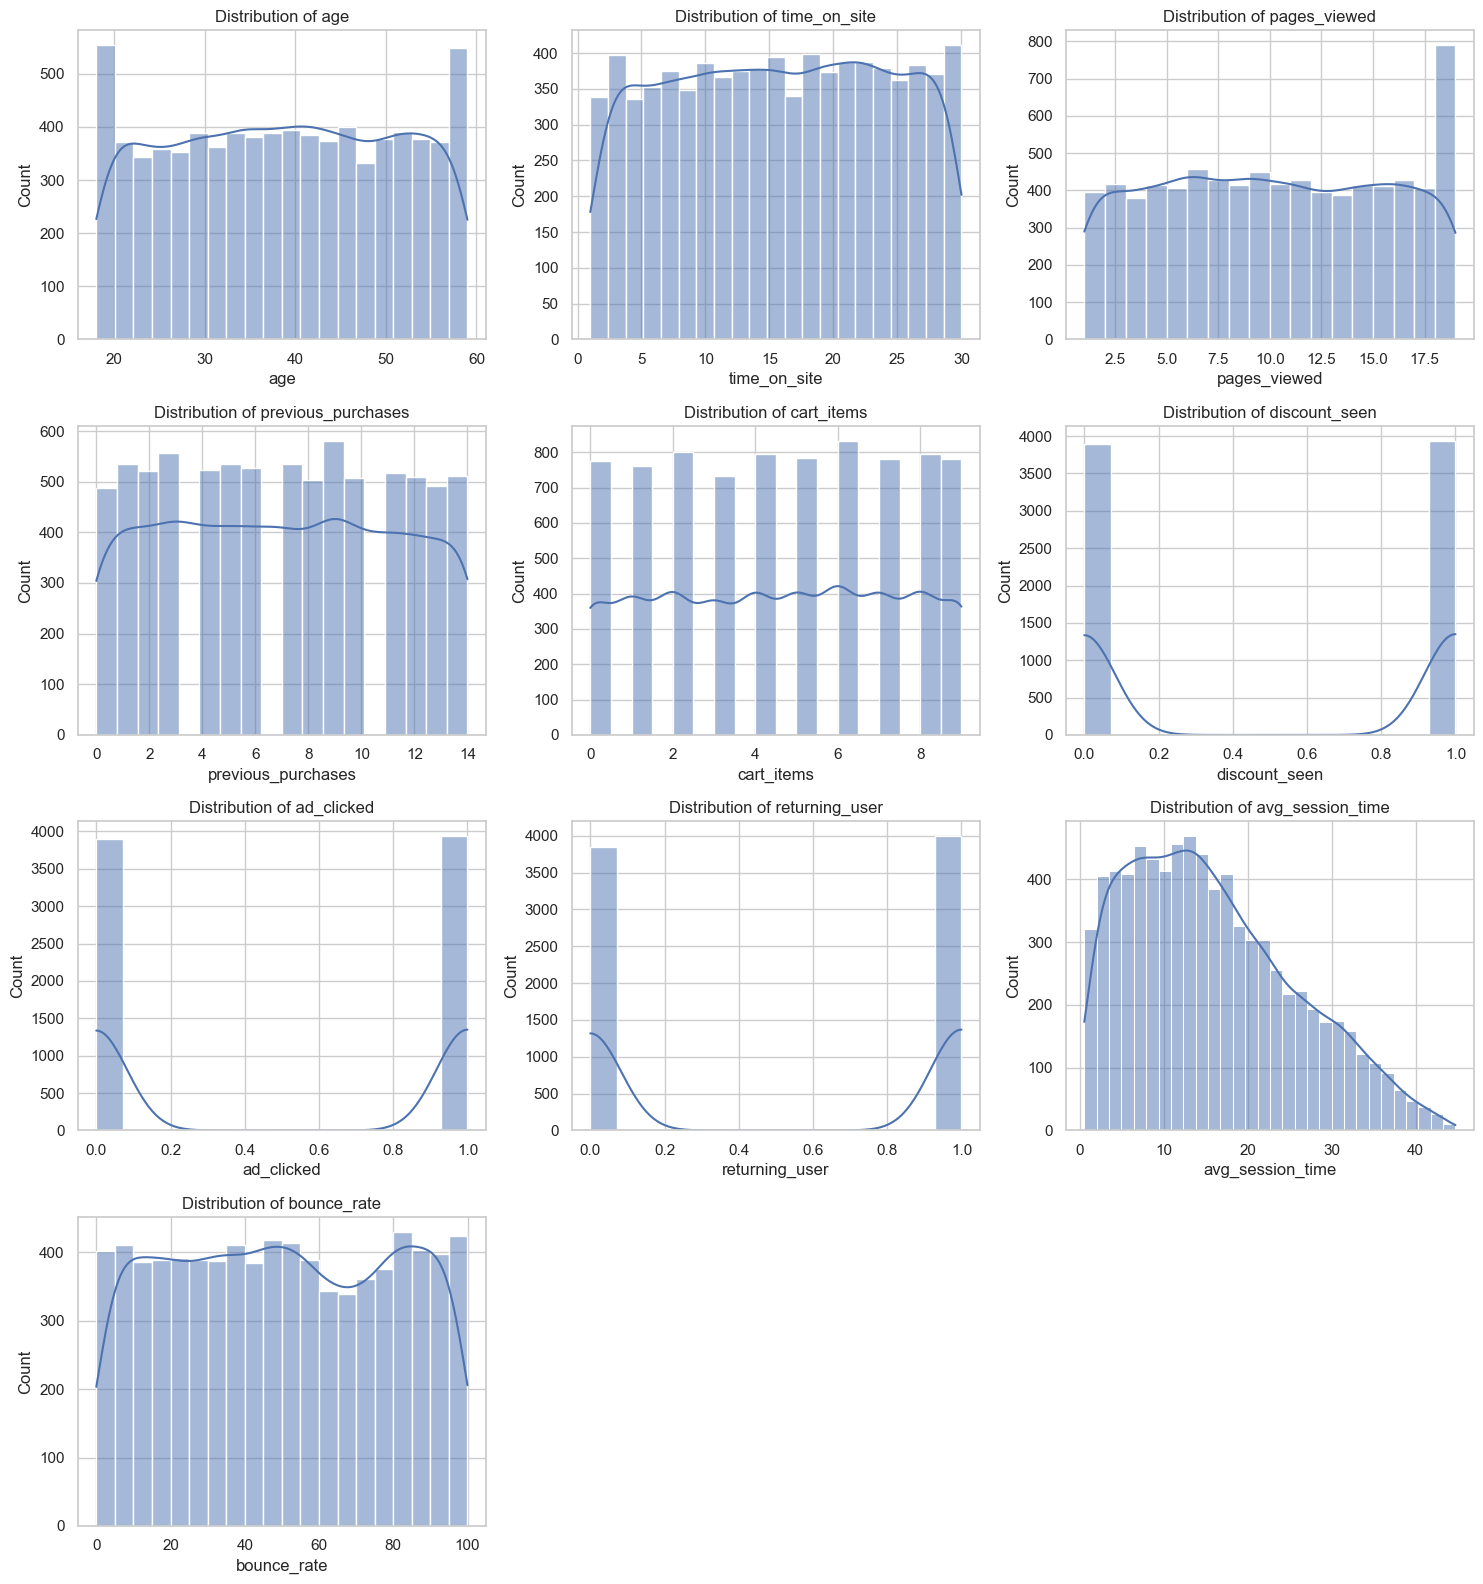

In [9]:
n_cols = 3
n_rows = math.ceil(len(feature_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes = np.atleast_1d(axes).flatten()

for i, col in enumerate(feature_cols):
    sns.histplot(data[col].dropna(), kde=True, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")

for j in range(len(feature_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

Outlier counts (IQR rule):


,outlier_count
avg_session_time,1
age,0
time_on_site,0
pages_viewed,0
previous_purchases,0
cart_items,0
discount_seen,0
ad_clicked,0
returning_user,0
bounce_rate,0


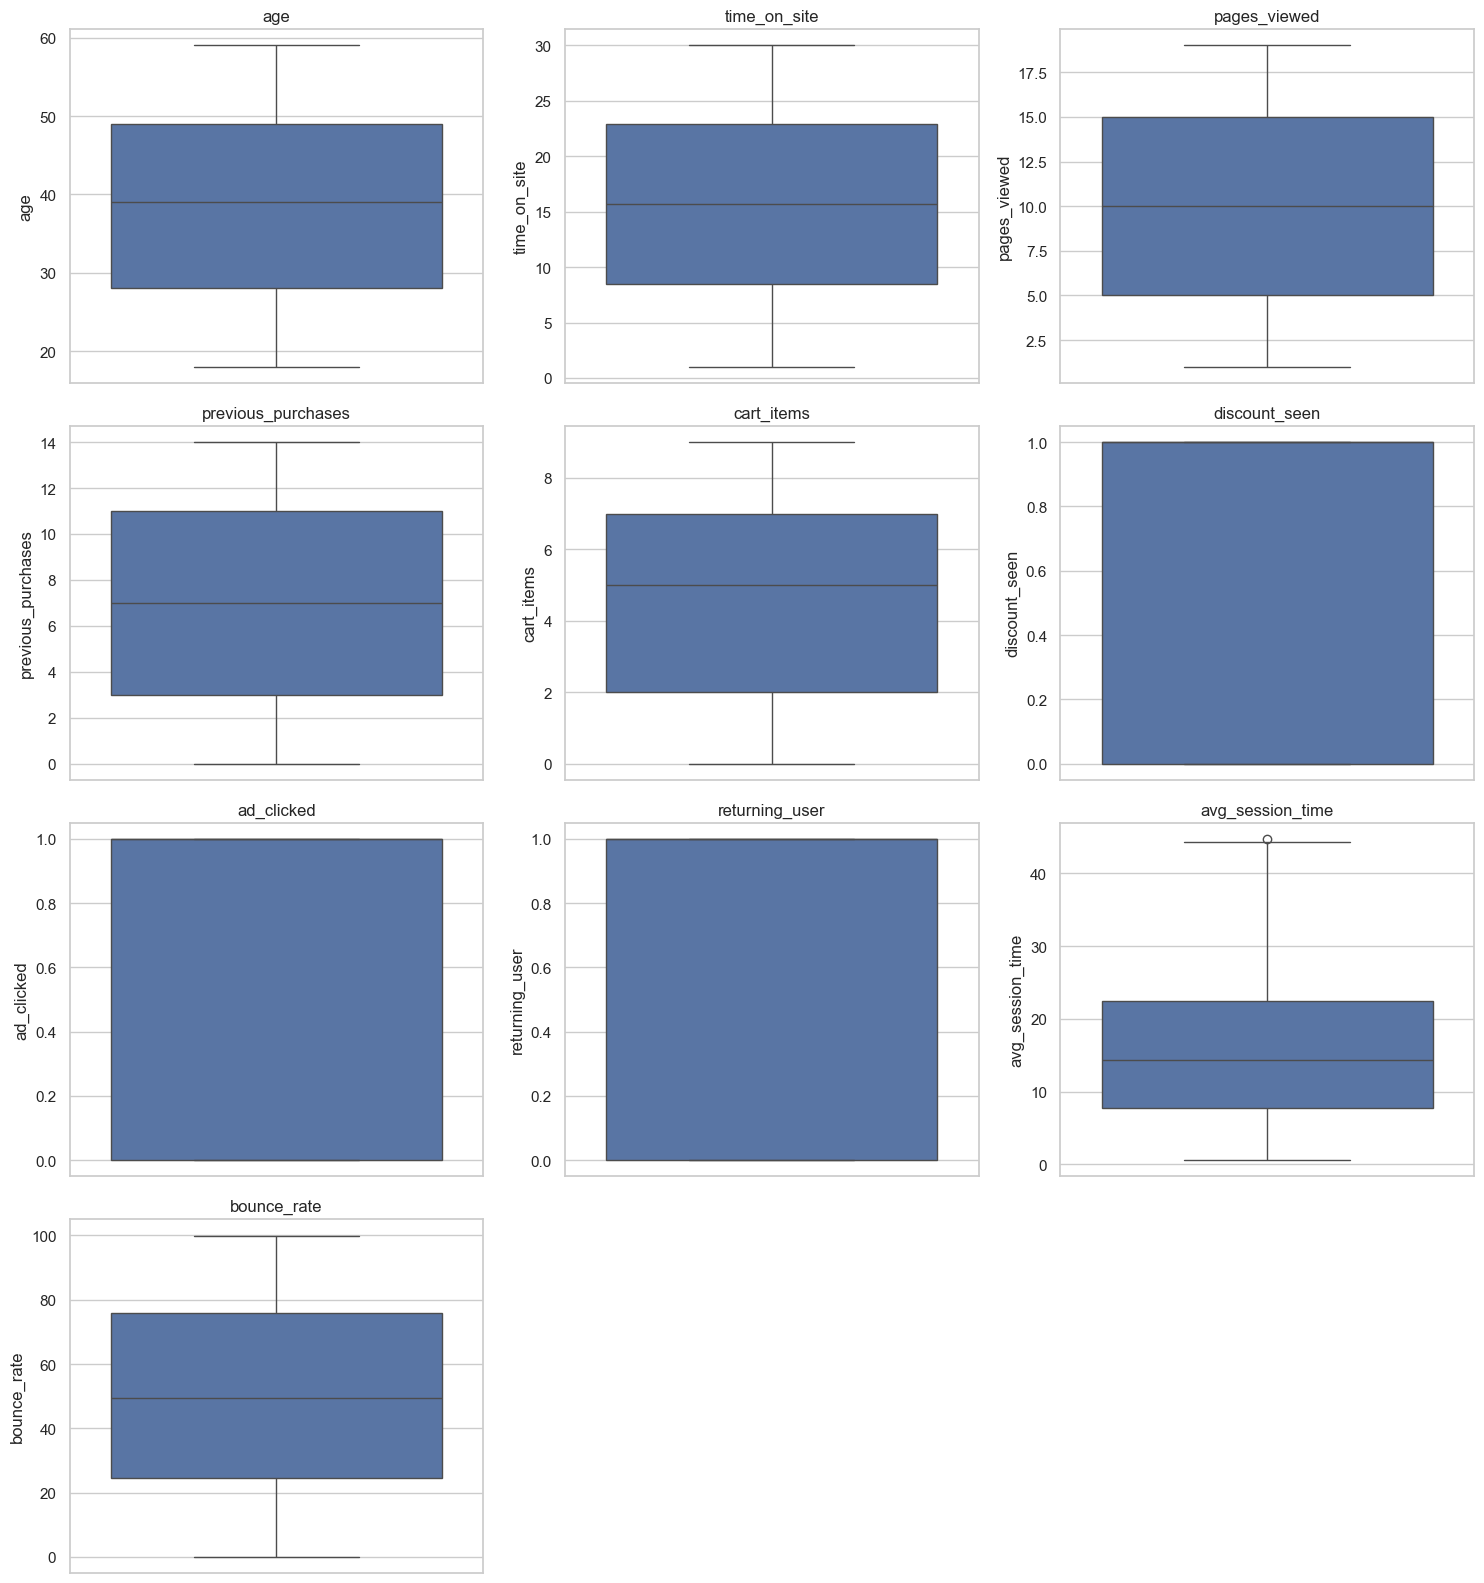

In [10]:
def count_outliers_iqr(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((series < lower) | (series > upper)).sum()

outlier_counts = {col: count_outliers_iqr(data[col].dropna()) for col in feature_cols}
outlier_df = pd.Series(outlier_counts, name="outlier_count").sort_values(ascending=False)
print("Outlier counts (IQR rule):")
display(outlier_df.to_frame())

n_cols = 3
n_rows = math.ceil(len(feature_cols) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes = np.atleast_1d(axes).flatten()

for i, col in enumerate(feature_cols):
    sns.boxplot(y=data[col].dropna(), ax=axes[i])
    axes[i].set_title(col)

for j in range(len(feature_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

## 4. Categorical features


gender value counts:
gender
Male      3931
Female    3909
NaN        160
Name: count, dtype: int64

device_type value counts:
device_type
Mobile     4685
Desktop    2365
Tablet      790
NaN         160
Name: count, dtype: int64


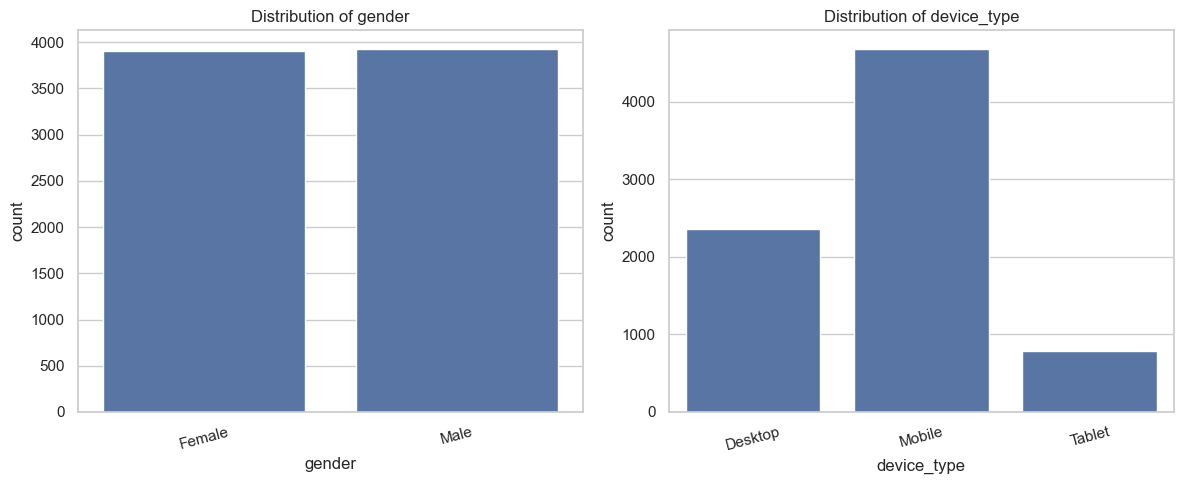

In [11]:
cat_cols = ["gender", "device_type"]

for col in cat_cols:
    print(f"\n{col} value counts:")
    print(data[col].value_counts(dropna=False))

fig, axes = plt.subplots(1, len(cat_cols), figsize=(6 * len(cat_cols), 5))
if len(cat_cols) == 1:
    axes = [axes]

for ax, col in zip(axes, cat_cols):
    sns.countplot(x=col, data=data, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

## 5. Categorical features vs purchase


gender vs purchase (row proportions):


purchase,0.0,1.0
gender,,
Female,0.0026,0.9974
Male,0.0008,0.9992



device_type vs purchase (row proportions):


purchase,0.0,1.0
device_type,,
Desktop,0.0013,0.9987
Mobile,0.0020,0.9980
Tablet,0.0013,0.9987


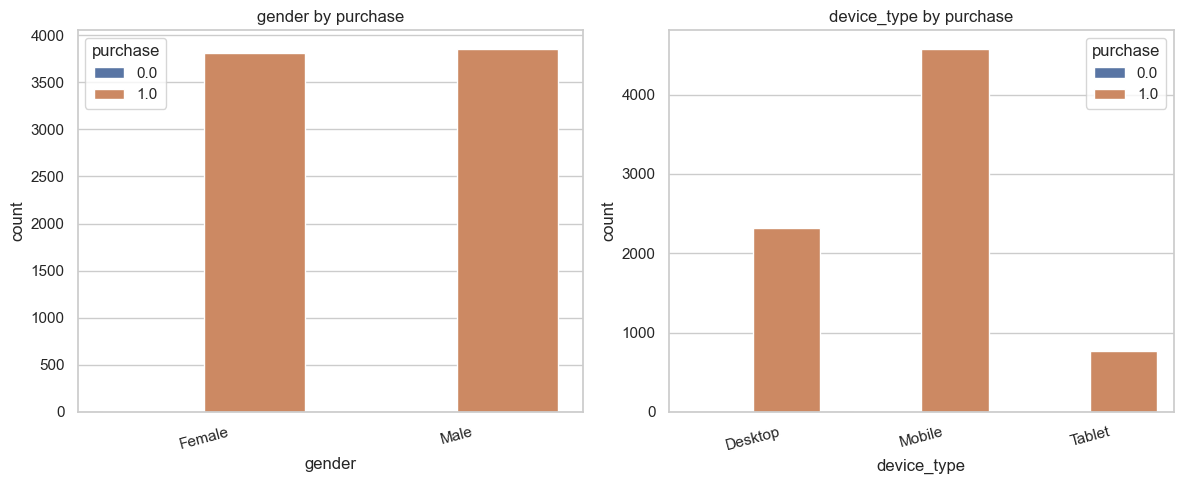

In [12]:
for col in cat_cols:
    print(f"\n{col} vs purchase (row proportions):")
    display(pd.crosstab(data[col], data["purchase"], normalize="index").round(4))

fig, axes = plt.subplots(1, len(cat_cols), figsize=(6 * len(cat_cols), 5))
if len(cat_cols) == 1:
    axes = [axes]

for ax, col in zip(axes, cat_cols):
    sns.countplot(x=col, hue="purchase", data=data, ax=ax)
    ax.set_title(f"{col} by purchase")
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


discount_seen vs purchase (row proportions):


purchase,0.0,1.0
discount_seen,,
0.0,0.0029,0.9971
1.0,0.0005,0.9995



ad_clicked vs purchase (row proportions):


purchase,0.0,1.0
ad_clicked,,
0.0,0.0016,0.9984
1.0,0.0018,0.9982



returning_user vs purchase (row proportions):


purchase,0.0,1.0
returning_user,,
0.0,0.0027,0.9973
1.0,0.0008,0.9992


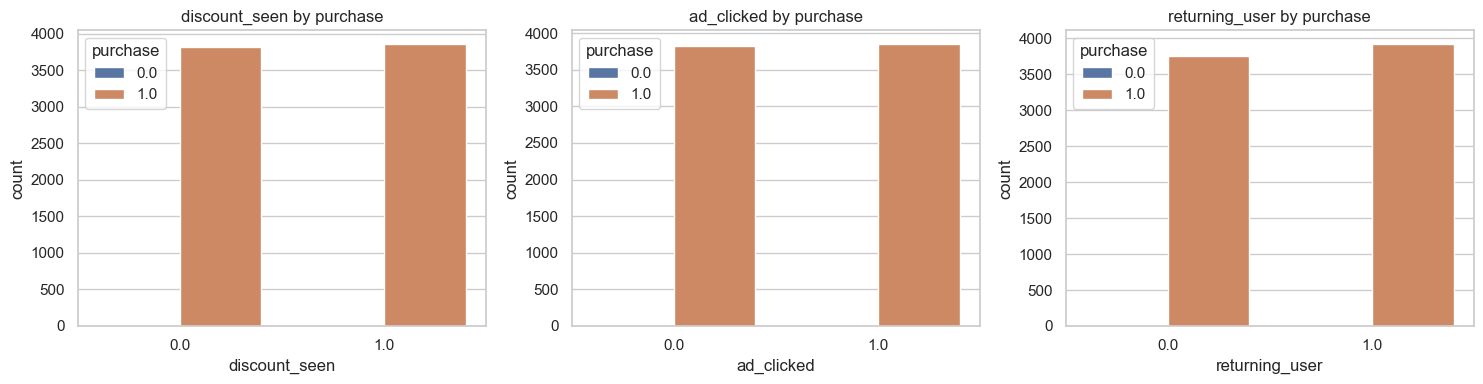

In [13]:
binary_cols = ["discount_seen", "ad_clicked", "returning_user"]
for col in binary_cols:
    print(f"\n{col} vs purchase (row proportions):")
    display(pd.crosstab(data[col], data["purchase"], normalize="index").round(4))

fig, axes = plt.subplots(1, len(binary_cols), figsize=(5 * len(binary_cols), 4))
for ax, col in zip(axes, binary_cols):
    sns.countplot(x=col, hue="purchase", data=data, ax=ax)
    ax.set_title(f"{col} by purchase")

plt.tight_layout()
plt.show()

## 6. Numerical features vs purchase

Mean values by purchase class:


,bounce_rate,time_on_site,pages_viewed,cart_items,previous_purchases
purchase,,,,,
0.0,88.63,3.63,6.54,0.46,1.38
1.0,49.86,15.72,9.98,4.54,6.98


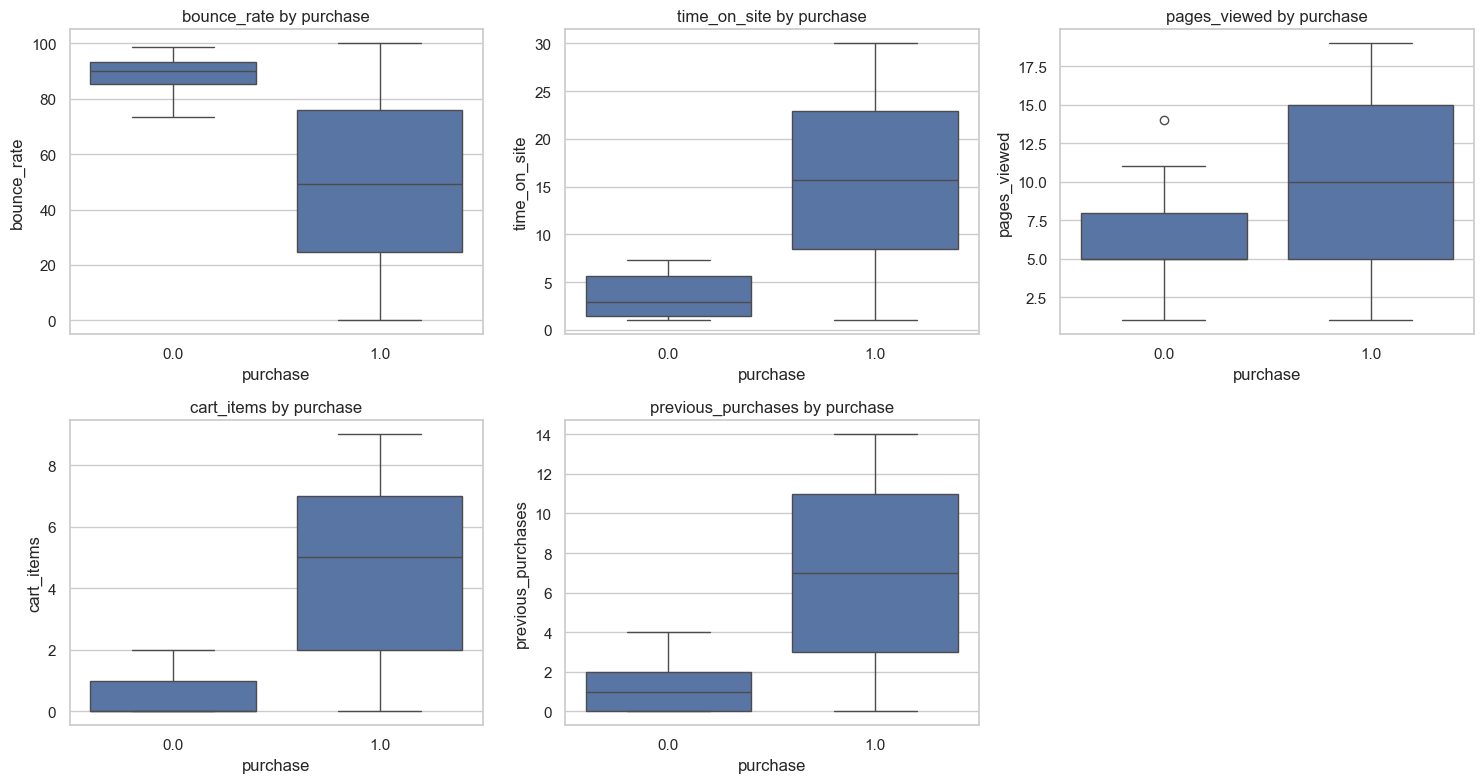

In [14]:
key_numeric = ["bounce_rate", "time_on_site", "pages_viewed", "cart_items", "previous_purchases"]

print("Mean values by purchase class:")
display(data.groupby("purchase")[key_numeric].mean().round(2))

n_cols = 3
n_rows = math.ceil(len(key_numeric) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes = np.atleast_1d(axes).flatten()

for i, col in enumerate(key_numeric):
    sns.boxplot(x="purchase", y=col, data=data, ax=axes[i])
    axes[i].set_title(f"{col} by purchase")

for j in range(len(key_numeric), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

## 8. Summary & preprocessing plan

Dataset: e-commerce user behavior (8000 rows, 14 columns)

Key findings:
- Missing values: 2240 total across all cells; main gaps in ad_clicked and related rows.
- Target imbalance: purchase=1 → 7827 rows (97.84%), purchase=0 → 13 rows (0.16%).
- user_id is an identifier (7840 unique values) — drop for modeling.
- time_on_site vs avg_session_time correlation: 0.85 — consider using only one.

Preprocessing plan:
1. Drop or exclude user_id from features.
2. Impute ad_clicked (mode) or drop rows with missing target/features.
3. One-hot encode gender and device_type.
4. Scale numerical features for neural networks.
5. Handle class imbalance (class weights, oversampling minority, or stratified split).
6. Train/validation/test split with stratification on purchase.

---

# Part 2 : Data preprocessing

Uses cleaned `data` from Part 1.

## 1. Working copy

In [19]:
df = data.copy()
print("Rows before cleaning:", len(df))

Rows before cleaning: 8000


## 2. Missing values

In [20]:
print("Missing per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Drop rows with missing target
df = df.dropna(subset=["purchase"])

# Drop rows with missing feature values (mainly ad_clicked)
feature_cols_raw = [c for c in df.columns if c not in ("user_id", "purchase")]
df = df.dropna(subset=feature_cols_raw)

print("Rows after dropping missing:", len(df))

Missing per column:
user_id               160
age                   160
gender                160
device_type           160
time_on_site          160
pages_viewed          160
previous_purchases    160
cart_items            160
discount_seen         160
ad_clicked            160
returning_user        160
avg_session_time      160
bounce_rate           160
purchase              160
dtype: int64
Rows after dropping missing: 6138


## 3. Target and features (drop `user_id`)

In [21]:
y = df["purchase"].astype(int)
X = df.drop(columns=["user_id", "purchase"])

print("Target distribution:")
print(y.value_counts())
print("\nFeature columns:", list(X.columns))

Target distribution:
purchase
1    6127
0      11
Name: count, dtype: int64

Feature columns: ['age', 'gender', 'device_type', 'time_on_site', 'pages_viewed', 'previous_purchases', 'cart_items', 'discount_seen', 'ad_clicked', 'returning_user', 'avg_session_time', 'bounce_rate']


## 4. Remove redundant feature

`time_on_site` and `avg_session_time` are highly correlated — keep `time_on_site` only.

In [22]:
X = X.drop(columns=["avg_session_time"])
print("Columns after dropping avg_session_time:", list(X.columns))

Columns after dropping avg_session_time: ['age', 'gender', 'device_type', 'time_on_site', 'pages_viewed', 'previous_purchases', 'cart_items', 'discount_seen', 'ad_clicked', 'returning_user', 'bounce_rate']


## 5. Encode categorical variables

In [23]:
X = pd.get_dummies(X, columns=["gender", "device_type"], drop_first=True)
print("Shape after one-hot encoding:", X.shape)
display(X.head())

Shape after one-hot encoding: (6138, 12)


,age,time_on_site,pages_viewed,previous_purchases,cart_items,discount_seen,ad_clicked,returning_user,bounce_rate,gender_Male,device_type_Mobile,device_type_Tablet
1,46.0,15.63,9.0,4.0,6.0,1.0,1.0,1.0,86.73,True,True,False
4,38.0,26.35,9.0,12.0,4.0,1.0,0.0,0.0,55.35,False,True,False
5,56.0,26.60,1.0,12.0,7.0,1.0,1.0,0.0,13.90,False,False,False
6,36.0,7.60,11.0,11.0,6.0,1.0,1.0,1.0,13.12,True,True,False
7,40.0,26.98,7.0,5.0,2.0,1.0,0.0,0.0,12.61,False,True,False


## 6. Outlier handling (IQR → median replacement)

In [24]:
numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()

def replace_outliers_with_median(frame, columns):
    out = frame.copy()
    for col in columns:
        q1, q3 = out[col].quantile(0.25), out[col].quantile(0.75)
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        median = out[col].median()
        out[col] = np.where((out[col] < lower) | (out[col] > upper), median, out[col])
    return out

X = replace_outliers_with_median(X, numeric_cols)
print("Outliers replaced with median for:", numeric_cols)

Outliers replaced with median for: ['age', 'time_on_site', 'pages_viewed', 'previous_purchases', 'cart_items', 'discount_seen', 'ad_clicked', 'returning_user', 'bounce_rate']


## 7. Train / validation / test split (stratified)

70% train, 15% validation, 15% test — stratified on `purchase`.

In [25]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

for name, y_split in [
    ("train", y_train),
    ("val", y_val),
    ("test", y_test),
]:
    print(f"{name}: {len(y_split)} rows, purchase rate = {y_split.mean():.4f}")


train: 4296 rows, purchase rate = 0.9981
val: 921 rows, purchase rate = 0.9989
test: 921 rows, purchase rate = 0.9978


## 8. Scale features (MinMaxScaler, fit on train only)

In [26]:
scaler = MinMaxScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index,
)
X_val_scaled = pd.DataFrame(
    scaler.transform(X_val),
    columns=X_val.columns,
    index=X_val.index,
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index,
)

print("Scaled train sample (first 3 rows):")
display(X_train_scaled.head(3))

Scaled train sample (first 3 rows):


,age,time_on_site,pages_viewed,previous_purchases,cart_items,discount_seen,ad_clicked,returning_user,bounce_rate,gender_Male,device_type_Mobile,device_type_Tablet
3044,0.536585,0.048982,0.388889,0.285714,0.888889,1.0,0.0,1.0,0.308023,1.0,0.0,0.0
5723,0.414634,0.947568,0.222222,0.214286,1.000000,1.0,0.0,1.0,0.334134,0.0,1.0,0.0
4084,0.951220,0.058296,0.888889,0.500000,0.555556,0.0,0.0,0.0,0.553922,0.0,1.0,0.0


## 9. Final checks

In [27]:
assert X_train_scaled.isnull().sum().sum() == 0
assert "user_id" not in X_train_scaled.columns
assert X_train_scaled.shape[1] == X_val_scaled.shape[1] == X_test_scaled.shape[1]

print("Feature count:", X_train_scaled.shape[1])
print("Train shape:", X_train_scaled.shape, "| Val:", X_val_scaled.shape, "| Test:", X_test_scaled.shape)
print("\nClass counts (train / val / test):")
print("  0:", (y_train == 0).sum(), (y_val == 0).sum(), (y_test == 0).sum())
print("  1:", (y_train == 1).sum(), (y_val == 1).sum(), (y_test == 1).sum())


Feature count: 12
Train shape: (4296, 12) | Val: (921, 12) | Test: (921, 12)

Class counts (train / val / test):
  0: 8 1 2
  1: 4288 920 919


In [28]:
def build_session_events(row):
    """Synthetic event funnel from one cleaned session row."""
    events = []
    n_view = max(1, min(int(row["pages_viewed"]), 12))
    events.extend(["view"] * n_view)
    if int(row.get("discount_seen", 0) or 0) == 1:
        events.append("discount")
    if int(row.get("ad_clicked", 0) or 0) == 1:
        events.append("click_ad")
    if int(row.get("cart_items", 0) or 0) > 0:
        events.extend(["cart"] * min(int(row["cart_items"]), 3))
    if int(row["purchase"]) == 1:
        events.append("purchase")
    return events


sessions = []
for idx, row in df.iterrows():
    ev = build_session_events(row)
    if len(ev) >= 2:
        sessions.append({"session_id": int(idx), "events": ev})

sessions_df = pd.DataFrame(sessions)
sessions_df["length"] = sessions_df["events"].apply(len)

train_idx = set(X_train.index.astype(int))
val_idx = set(X_val.index.astype(int))
test_idx = set(X_test.index.astype(int))

train_sessions = sessions_df[sessions_df["session_id"].isin(train_idx)].copy()
val_sessions = sessions_df[sessions_df["session_id"].isin(val_idx)].copy()
test_sessions = sessions_df[sessions_df["session_id"].isin(test_idx)].copy()

all_events = sorted({e for ev in sessions_df["events"] for e in ev})
PAD_TOKEN = "<pad>"
event2id = {PAD_TOKEN: 0, **{e: i + 1 for i, e in enumerate(all_events)}}
id2event = {v: k for k, v in event2id.items()}
NUM_EVENTS = len(event2id)
PAD_IDX = event2id[PAD_TOKEN]

# Aliases used in sequence modelling below
train_df, val_df, test_df = train_sessions, val_sessions, test_sessions

print(f"Sessions: {len(sessions_df)} | train/val/test: {len(train_df)}/{len(val_df)}/{len(test_df)}")
print("Event vocabulary:", event2id)
print("Sequence length stats:")
print(sessions_df["length"].describe())


Sessions: 6138 | train/val/test: 4296/921/921
Event vocabulary: {'<pad>': 0, 'cart': 1, 'click_ad': 2, 'discount': 3, 'purchase': 4, 'view': 5}
Sequence length stats:
count    6138.000000
mean       12.959107
std         3.974555
min         2.000000
25%        10.000000
50%        14.000000
75%        16.000000
max        18.000000
Name: length, dtype: float64


---

# Part 3 : Sequence modelling (RNN / LSTM)

Next-event prediction on session sequences from Part 2.

In [29]:
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

print(f"Ready for modelling — train: {len(train_df)} | val: {len(val_df)} | test: {len(test_df)} sequences")
display(train_df.head(3))


Ready for modelling — train: 4296 | val: 921 | test: 921 sequences


,session_id,events,length
0,1,"[view, view, view, view, view, view, view, vie...",15
6,9,"[view, view, view, cart, cart, cart, purchase]",7
7,10,"[view, view, view, view, view, view, view, vie...",17


## 2. PyTorch dataset (next-event prediction)

In [30]:
def encode_events(event_list):
    return [event2id[e] for e in event_list]


class NextEventDataset(Dataset):
    def __init__(self, frame):
        self.samples = []
        for events in frame["events"].tolist():
            ids = encode_events(events)
            self.samples.append((ids[:-1], ids[1:]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        x, y = self.samples[idx]
        return (
            torch.tensor(x, dtype=torch.long),
            torch.tensor(y, dtype=torch.long),
        )


def collate_batch(batch):
    xs, ys = zip(*batch)
    x_pad = pad_sequence(xs, batch_first=True, padding_value=PAD_IDX)
    y_pad = pad_sequence(ys, batch_first=True, padding_value=PAD_IDX)
    lengths = torch.tensor([len(x) for x in xs], dtype=torch.long)
    return x_pad, y_pad, lengths

## 3. Models: RNN and LSTM

In [31]:
class NextEventModel(nn.Module):
    def __init__(
        self,
        num_events,
        embed_dim,
        hidden_size,
        num_layers,
        dropout,
        rnn_type="RNN",
    ):
        super().__init__()
        self.rnn_type = rnn_type
        self.embedding = nn.Embedding(num_events, embed_dim, padding_idx=PAD_IDX)
        rnn_dropout = dropout if num_layers > 1 else 0.0
        if rnn_type == "LSTM":
            self.rnn = nn.LSTM(
                embed_dim,
                hidden_size,
                num_layers=num_layers,
                batch_first=True,
                dropout=rnn_dropout,
            )
        else:
            self.rnn = nn.RNN(
                embed_dim,
                hidden_size,
                num_layers=num_layers,
                batch_first=True,
                dropout=rnn_dropout,
            )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, num_events)

    def forward(self, x):
        emb = self.embedding(x)
        out, _ = self.rnn(emb)
        out = self.dropout(out)
        return self.fc(out)


def run_epoch(model, loader, criterion, optimizer=None):
    train_mode = optimizer is not None
    model.train(train_mode)
    total_loss = 0.0
    all_preds, all_targets = [], []

    for x, y, lengths in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)

        # mask padding positions
        mask = y != PAD_IDX
        loss = criterion(logits[mask], y[mask])

        if train_mode:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        total_loss += loss.item() * mask.sum().item()
        preds = logits.argmax(dim=-1)
        all_preds.extend(preds[mask].cpu().numpy())
        all_targets.extend(y[mask].cpu().numpy())

    n = len(all_targets)
    avg_loss = total_loss / max(n, 1)

    if n:
        acc = accuracy_score(all_targets, all_preds)
        f1_weighted = f1_score(all_targets, all_preds, average="weighted", zero_division=0)
        f1_macro = f1_score(all_targets, all_preds, average="macro", zero_division=0)
    else:
        acc, f1_weighted, f1_macro = 0.0, 0.0, 0.0

    return avg_loss, acc, f1_weighted, f1_macro


def train_model(
    rnn_type,
    hidden_size,
    num_layers,
    dropout,
    embed_dim,
    lr,
    batch_size,
    max_epochs=40,
    patience=6,
):
    train_loader = DataLoader(
        NextEventDataset(train_df),
        batch_size=batch_size,
        shuffle=True,
        collate_fn=collate_batch,
    )
    val_loader = DataLoader(
        NextEventDataset(val_df),
        batch_size=batch_size,
        shuffle=False,
        collate_fn=collate_batch,
    )

    model = NextEventModel(
        NUM_EVENTS,
        embed_dim,
        hidden_size,
        num_layers,
        dropout,
        rnn_type=rnn_type,
    ).to(DEVICE)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
        "train_f1_weighted": [],
        "val_f1_weighted": [],
        "train_f1_macro": [],
        "val_f1_macro": [],
    }
    best_val_loss = float("inf")
    best_state = None
    wait = 0

    for epoch in range(1, max_epochs + 1):
        tr_loss, tr_acc, tr_f1w, tr_f1m = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc, va_f1w, va_f1m = run_epoch(model, val_loader, criterion)

        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(va_acc)
        history["train_f1_weighted"].append(tr_f1w)
        history["val_f1_weighted"].append(va_f1w)
        history["train_f1_macro"].append(tr_f1m)
        history["val_f1_macro"].append(va_f1m)

        if va_loss < best_val_loss:
            best_val_loss = va_loss
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history, best_val_loss

## 5. Hyperparameter search : RNN

In [32]:
# Grid: 3 x 2 x 2 = 12 configs per model (expand lists for a wider search)
param_grid = {
    "hidden_size": [64, 128, 256],
    "num_layers": [1, 2],
    "dropout": [0.0, 0.2],
    "embed_dim": [64],
    "lr": [1e-3],
    "batch_size": [32],
}

rnn_configs = [
    dict(zip(param_grid.keys(), vals))
    for vals in product(*param_grid.values())
]
print("Configurations per model (RNN and LSTM):", len(rnn_configs))

Configurations per model (RNN and LSTM): 12


In [33]:
rnn_results = []

for i, cfg in enumerate(rnn_configs):
    print(f"\n[RNN {i+1}/{len(rnn_configs)}] {cfg}")
    torch.manual_seed(RANDOM_STATE)
    model, hist, best_val_loss = train_model(rnn_type="RNN", **cfg)

    # metrics for the final (best-weights-loaded) model
    val_loader = DataLoader(
        NextEventDataset(val_df),
        batch_size=cfg["batch_size"],
        shuffle=False,
        collate_fn=collate_batch,
    )
    _, val_acc, val_f1w, val_f1m = run_epoch(model, val_loader, nn.CrossEntropyLoss())

    rnn_results.append(
        {
            "model": "RNN",
            "run": i,
            **cfg,
            "best_val_loss": best_val_loss,
            "best_val_acc": max(hist["val_acc"]) if hist["val_acc"] else 0,
            "best_val_f1_weighted": max(hist["val_f1_weighted"]) if hist["val_f1_weighted"] else 0,
            "best_val_f1_macro": max(hist["val_f1_macro"]) if hist["val_f1_macro"] else 0,
            "final_val_acc": val_acc,
            "final_val_f1_weighted": val_f1w,
            "final_val_f1_macro": val_f1m,
            "epochs_ran": len(hist["val_loss"]),
            "history": hist,
            "state_dict": {k: v.cpu().clone() for k, v in model.state_dict().items()},
        }
    )

rnn_results_df = pd.DataFrame(
    [{k: v for k, v in r.items() if k not in ("history", "state_dict")} for r in rnn_results]
)
rnn_results_df = rnn_results_df.sort_values("best_val_loss")
print("\nRNN results (sorted by val loss):")
display(rnn_results_df.head(10))

print("\nRNN results (sorted by final val F1 weighted):")
display(rnn_results_df.sort_values("final_val_f1_weighted", ascending=False).head(10))



[RNN 1/12] {'hidden_size': 64, 'num_layers': 1, 'dropout': 0.0, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[RNN 2/12] {'hidden_size': 64, 'num_layers': 1, 'dropout': 0.2, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[RNN 3/12] {'hidden_size': 64, 'num_layers': 2, 'dropout': 0.0, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[RNN 4/12] {'hidden_size': 64, 'num_layers': 2, 'dropout': 0.2, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[RNN 5/12] {'hidden_size': 128, 'num_layers': 1, 'dropout': 0.0, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[RNN 6/12] {'hidden_size': 128, 'num_layers': 1, 'dropout': 0.2, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[RNN 7/12] {'hidden_size': 128, 'num_layers': 2, 'dropout': 0.0, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[RNN 8/12] {'hidden_size': 128, 'num_layers': 2, 'dropout': 0.2, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[RNN 9/12] {'hidden_size': 256, 'num_layers': 1, 'dropout': 0.0, 'embed_dim': 64, 'lr': 0.0

,model,run,hidden_size,num_layers,dropout,embed_dim,lr,batch_size,best_val_loss,best_val_acc,best_val_f1_weighted,best_val_f1_macro,final_val_acc,final_val_f1_weighted,final_val_f1_macro,epochs_ran
4,RNN,4,128,1,0.0,64,0.001,32,0.373583,0.891573,0.885075,0.713304,0.890383,0.884077,0.707656,26
2,RNN,2,64,2,0.0,64,0.001,32,0.373991,0.891298,0.885075,0.713304,0.890383,0.885075,0.713304,31
6,RNN,6,128,2,0.0,64,0.001,32,0.374277,0.891298,0.885075,0.713304,0.890841,0.882824,0.700151,23
11,RNN,11,256,2,0.2,64,0.001,32,0.374529,0.891298,0.885075,0.713304,0.890749,0.885004,0.711691,15
8,RNN,8,256,1,0.0,64,0.001,32,0.374698,0.891298,0.885075,0.713304,0.890383,0.880036,0.687465,26
7,RNN,7,128,2,0.2,64,0.001,32,0.374846,0.891298,0.885075,0.713304,0.888370,0.874014,0.662681,26
10,RNN,10,256,2,0.0,64,0.001,32,0.375364,0.890932,0.885075,0.713304,0.888187,0.868104,0.634911,14
3,RNN,3,64,2,0.2,64,0.001,32,0.375501,0.890841,0.885075,0.713304,0.890383,0.885075,0.713304,33
9,RNN,9,256,1,0.2,64,0.001,32,0.375876,0.891573,0.885075,0.713304,0.889102,0.873837,0.660412,13
5,RNN,5,128,1,0.2,64,0.001,32,0.376852,0.890841,0.885075,0.713304,0.887638,0.876536,0.676677,15



RNN results (sorted by final val F1 weighted):


,model,run,hidden_size,num_layers,dropout,embed_dim,lr,batch_size,best_val_loss,best_val_acc,best_val_f1_weighted,best_val_f1_macro,final_val_acc,final_val_f1_weighted,final_val_f1_macro,epochs_ran
2,RNN,2,64,2,0.0,64,0.001,32,0.373991,0.891298,0.885075,0.713304,0.890383,0.885075,0.713304,31
3,RNN,3,64,2,0.2,64,0.001,32,0.375501,0.890841,0.885075,0.713304,0.890383,0.885075,0.713304,33
11,RNN,11,256,2,0.2,64,0.001,32,0.374529,0.891298,0.885075,0.713304,0.890749,0.885004,0.711691,15
4,RNN,4,128,1,0.0,64,0.001,32,0.373583,0.891573,0.885075,0.713304,0.890383,0.884077,0.707656,26
0,RNN,0,64,1,0.0,64,0.001,32,0.377230,0.890841,0.885075,0.713304,0.890841,0.883395,0.703277,18
6,RNN,6,128,2,0.0,64,0.001,32,0.374277,0.891298,0.885075,0.713304,0.890841,0.882824,0.700151,23
8,RNN,8,256,1,0.0,64,0.001,32,0.374698,0.891298,0.885075,0.713304,0.890383,0.880036,0.687465,26
5,RNN,5,128,1,0.2,64,0.001,32,0.376852,0.890841,0.885075,0.713304,0.887638,0.876536,0.676677,15
7,RNN,7,128,2,0.2,64,0.001,32,0.374846,0.891298,0.885075,0.713304,0.888370,0.874014,0.662681,26
9,RNN,9,256,1,0.2,64,0.001,32,0.375876,0.891573,0.885075,0.713304,0.889102,0.873837,0.660412,13


Best RNN config:


,model,run,hidden_size,num_layers,dropout,embed_dim,lr,batch_size,best_val_loss,best_val_acc,best_val_f1_weighted,best_val_f1_macro,final_val_acc,final_val_f1_weighted,final_val_f1_macro,epochs_ran
0,RNN,4,128,1,0.0,64,0.001,32,0.373583,0.891573,0.885075,0.713304,0.890383,0.884077,0.707656,26


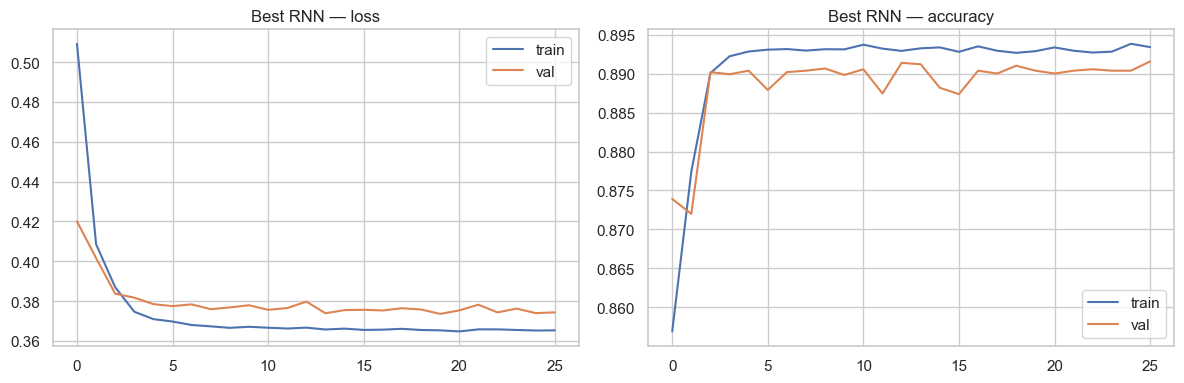

In [34]:
best_rnn = min(rnn_results, key=lambda r: r["best_val_loss"])
print("Best RNN config:")
display(pd.DataFrame([{k: v for k, v in best_rnn.items() if k not in ("history", "state_dict")}]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(best_rnn["history"]["train_loss"], label="train")
axes[0].plot(best_rnn["history"]["val_loss"], label="val")
axes[0].set_title("Best RNN — loss")
axes[0].legend()
axes[1].plot(best_rnn["history"]["train_acc"], label="train")
axes[1].plot(best_rnn["history"]["val_acc"], label="val")
axes[1].set_title("Best RNN — accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

## 6. Hyperparameter search : LSTM

In [35]:
lstm_results = []

for i, cfg in enumerate(rnn_configs):
    print(f"\n[LSTM {i+1}/{len(rnn_configs)}] {cfg}")
    torch.manual_seed(RANDOM_STATE)
    model, hist, best_val_loss = train_model(rnn_type="LSTM", **cfg)

    # metrics for the final (best-weights-loaded) model
    val_loader = DataLoader(
        NextEventDataset(val_df),
        batch_size=cfg["batch_size"],
        shuffle=False,
        collate_fn=collate_batch,
    )
    _, val_acc, val_f1w, val_f1m = run_epoch(model, val_loader, nn.CrossEntropyLoss())

    lstm_results.append(
        {
            "model": "LSTM",
            "run": i,
            **cfg,
            "best_val_loss": best_val_loss,
            "best_val_acc": max(hist["val_acc"]) if hist["val_acc"] else 0,
            "best_val_f1_weighted": max(hist["val_f1_weighted"]) if hist["val_f1_weighted"] else 0,
            "best_val_f1_macro": max(hist["val_f1_macro"]) if hist["val_f1_macro"] else 0,
            "final_val_acc": val_acc,
            "final_val_f1_weighted": val_f1w,
            "final_val_f1_macro": val_f1m,
            "epochs_ran": len(hist["val_loss"]),
            "history": hist,
            "state_dict": {k: v.cpu().clone() for k, v in model.state_dict().items()},
        }
    )

lstm_results_df = pd.DataFrame(
    [{k: v for k, v in r.items() if k not in ("history", "state_dict")} for r in lstm_results]
)
lstm_results_df = lstm_results_df.sort_values("best_val_loss")
print("\nLSTM results (sorted by val loss):")
display(lstm_results_df.head(10))

print("\nLSTM results (sorted by final val F1 weighted):")
display(lstm_results_df.sort_values("final_val_f1_weighted", ascending=False).head(10))



[LSTM 1/12] {'hidden_size': 64, 'num_layers': 1, 'dropout': 0.0, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[LSTM 2/12] {'hidden_size': 64, 'num_layers': 1, 'dropout': 0.2, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[LSTM 3/12] {'hidden_size': 64, 'num_layers': 2, 'dropout': 0.0, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[LSTM 4/12] {'hidden_size': 64, 'num_layers': 2, 'dropout': 0.2, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[LSTM 5/12] {'hidden_size': 128, 'num_layers': 1, 'dropout': 0.0, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[LSTM 6/12] {'hidden_size': 128, 'num_layers': 1, 'dropout': 0.2, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[LSTM 7/12] {'hidden_size': 128, 'num_layers': 2, 'dropout': 0.0, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[LSTM 8/12] {'hidden_size': 128, 'num_layers': 2, 'dropout': 0.2, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[LSTM 9/12] {'hidden_size': 256, 'num_layers': 1, 'dropout': 0.0, 'embed_dim': 64, 

,model,run,hidden_size,num_layers,dropout,embed_dim,lr,batch_size,best_val_loss,best_val_acc,best_val_f1_weighted,best_val_f1_macro,final_val_acc,final_val_f1_weighted,final_val_f1_macro,epochs_ran
3,LSTM,3,64,2,0.2,64,0.001,32,0.374103,0.890932,0.885075,0.713304,0.890932,0.882932,0.700640,34
8,LSTM,8,256,1,0.0,64,0.001,32,0.374189,0.890383,0.885075,0.713304,0.890383,0.885075,0.713304,14
0,LSTM,0,64,1,0.0,64,0.001,32,0.374263,0.890932,0.885075,0.713304,0.890292,0.883517,0.705085,28
7,LSTM,7,128,2,0.2,64,0.001,32,0.374295,0.891024,0.885075,0.713304,0.890566,0.883847,0.705961,23
2,LSTM,2,64,2,0.0,64,0.001,32,0.374369,0.890932,0.885075,0.713304,0.890383,0.885075,0.713304,22
1,LSTM,1,64,1,0.2,64,0.001,32,0.374379,0.891298,0.885075,0.713304,0.890932,0.882932,0.700640,39
11,LSTM,11,256,2,0.2,64,0.001,32,0.374422,0.891024,0.885075,0.713304,0.890383,0.885075,0.713304,15
10,LSTM,10,256,2,0.0,64,0.001,32,0.374524,0.890383,0.885075,0.713304,0.887364,0.875271,0.670989,17
6,LSTM,6,128,2,0.0,64,0.001,32,0.374972,0.890383,0.885075,0.713304,0.889743,0.883486,0.706407,20
9,LSTM,9,256,1,0.2,64,0.001,32,0.375398,0.890383,0.885075,0.713304,0.890200,0.881326,0.694142,15



LSTM results (sorted by final val F1 weighted):


,model,run,hidden_size,num_layers,dropout,embed_dim,lr,batch_size,best_val_loss,best_val_acc,best_val_f1_weighted,best_val_f1_macro,final_val_acc,final_val_f1_weighted,final_val_f1_macro,epochs_ran
8,LSTM,8,256,1,0.0,64,0.001,32,0.374189,0.890383,0.885075,0.713304,0.890383,0.885075,0.713304,14
2,LSTM,2,64,2,0.0,64,0.001,32,0.374369,0.890932,0.885075,0.713304,0.890383,0.885075,0.713304,22
11,LSTM,11,256,2,0.2,64,0.001,32,0.374422,0.891024,0.885075,0.713304,0.890383,0.885075,0.713304,15
4,LSTM,4,128,1,0.0,64,0.001,32,0.375652,0.891298,0.885075,0.713304,0.891298,0.884967,0.710255,19
7,LSTM,7,128,2,0.2,64,0.001,32,0.374295,0.891024,0.885075,0.713304,0.890566,0.883847,0.705961,23
0,LSTM,0,64,1,0.0,64,0.001,32,0.374263,0.890932,0.885075,0.713304,0.890292,0.883517,0.705085,28
6,LSTM,6,128,2,0.0,64,0.001,32,0.374972,0.890383,0.885075,0.713304,0.889743,0.883486,0.706407,20
3,LSTM,3,64,2,0.2,64,0.001,32,0.374103,0.890932,0.885075,0.713304,0.890932,0.882932,0.700640,34
1,LSTM,1,64,1,0.2,64,0.001,32,0.374379,0.891298,0.885075,0.713304,0.890932,0.882932,0.700640,39
9,LSTM,9,256,1,0.2,64,0.001,32,0.375398,0.890383,0.885075,0.713304,0.890200,0.881326,0.694142,15


Best LSTM config:


,model,run,hidden_size,num_layers,dropout,embed_dim,lr,batch_size,best_val_loss,best_val_acc,best_val_f1_weighted,best_val_f1_macro,final_val_acc,final_val_f1_weighted,final_val_f1_macro,epochs_ran
0,LSTM,3,64,2,0.2,64,0.001,32,0.374103,0.890932,0.885075,0.713304,0.890932,0.882932,0.70064,34


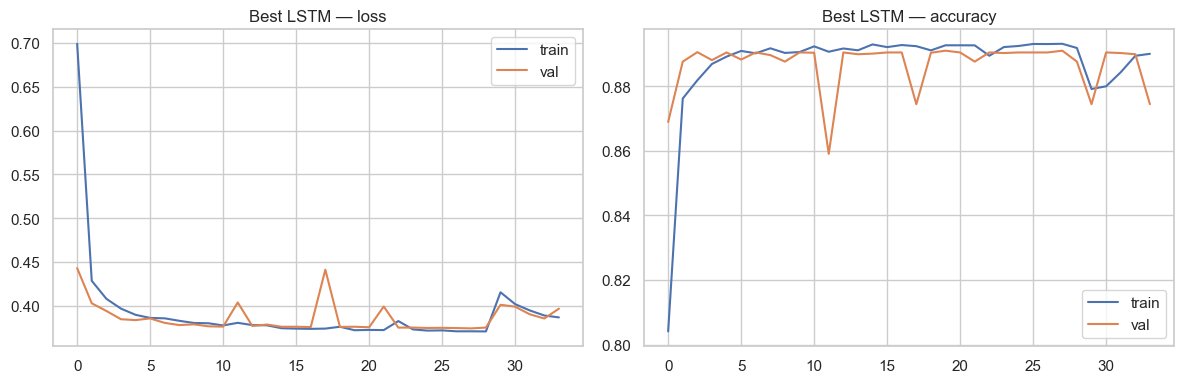

In [36]:
best_lstm = min(lstm_results, key=lambda r: r["best_val_loss"])
print("Best LSTM config:")
display(pd.DataFrame([{k: v for k, v in best_lstm.items() if k not in ("history", "state_dict")}]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(best_lstm["history"]["train_loss"], label="train")
axes[0].plot(best_lstm["history"]["val_loss"], label="val")
axes[0].set_title("Best LSTM — loss")
axes[0].legend()
axes[1].plot(best_lstm["history"]["train_acc"], label="train")
axes[1].plot(best_lstm["history"]["val_acc"], label="val")
axes[1].set_title("Best LSTM — accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

## 7. Test-set evaluation (best RNN vs best LSTM)

In [40]:
def evaluate_on_test(result_row):
    cfg = {k: result_row[k] for k in ["hidden_size", "num_layers", "dropout", "embed_dim", "lr", "batch_size"]}
    model = NextEventModel(
        NUM_EVENTS,
        cfg["embed_dim"],
        cfg["hidden_size"],
        cfg["num_layers"],
        cfg["dropout"],
        rnn_type=result_row["model"],
    ).to(DEVICE)
    model.load_state_dict(result_row["state_dict"])

    test_loader = DataLoader(
        NextEventDataset(test_df),
        batch_size=cfg["batch_size"],
        shuffle=False,
        collate_fn=collate_batch,
    )
    loss, acc, f1w, f1m = run_epoch(model, test_loader, nn.CrossEntropyLoss())
    return loss, acc, f1w, f1m, model


rnn_test_loss, rnn_test_acc, rnn_test_f1w, rnn_test_f1m, rnn_model = evaluate_on_test(best_rnn)
lstm_test_loss, lstm_test_acc, lstm_test_f1w, lstm_test_f1m, lstm_model = evaluate_on_test(best_lstm)

comparison = pd.DataFrame(
    [
        {
            "model": "RNN (best)",
            "hidden_size": best_rnn["hidden_size"],
            "num_layers": best_rnn["num_layers"],
            "dropout": best_rnn["dropout"],
            "embed_dim": best_rnn["embed_dim"],
            "lr": best_rnn["lr"],
            "val_loss": best_rnn["best_val_loss"],
            "val_acc": best_rnn["best_val_acc"],
            "val_f1_weighted": best_rnn["final_val_f1_weighted"],
            "test_loss": rnn_test_loss,
            "test_acc": rnn_test_acc,
            "test_f1_weighted": rnn_test_f1w,
            "test_f1_macro": rnn_test_f1m,
        },
        {
            "model": "LSTM (best)",
            "hidden_size": best_lstm["hidden_size"],
            "num_layers": best_lstm["num_layers"],
            "dropout": best_lstm["dropout"],
            "embed_dim": best_lstm["embed_dim"],
            "lr": best_lstm["lr"],
            "val_loss": best_lstm["best_val_loss"],
            "val_acc": best_lstm["best_val_acc"],
            "val_f1_weighted": best_lstm["final_val_f1_weighted"],
            "test_loss": lstm_test_loss,
            "test_acc": lstm_test_acc,
            "test_f1_weighted": lstm_test_f1w,
            "test_f1_macro": lstm_test_f1m,
        },
    ]
)
print("Final comparison (validation + test):")
display(comparison)

winner_acc = "LSTM" if lstm_test_acc > rnn_test_acc else "RNN"
winner_f1 = "LSTM" if lstm_test_f1w > rnn_test_f1w else "RNN"
print(f"\nWinner on test accuracy: {winner_acc}")
print(f"Winner on test F1 (weighted): {winner_f1}")


Final comparison (validation + test):


,model,hidden_size,num_layers,dropout,embed_dim,lr,val_loss,val_acc,val_f1_weighted,test_loss,test_acc,test_f1_weighted,test_f1_macro
0,RNN (best),128,1,0.0,64,0.001,0.373583,0.891573,0.884077,0.380988,0.887076,0.881022,0.699841
1,LSTM (best),64,2,0.2,64,0.001,0.374103,0.890932,0.882932,0.381058,0.888182,0.880702,0.694343



Winner on test accuracy: LSTM
Winner on test F1 (weighted): RNN


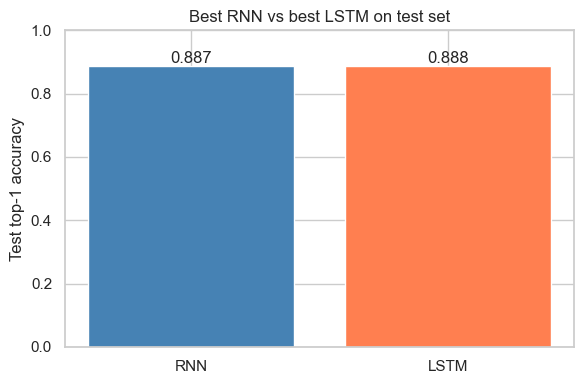

In [41]:
fig, ax = plt.subplots(figsize=(6, 4))
x = ["RNN", "LSTM"]
vals = [rnn_test_acc, lstm_test_acc]
ax.bar(x, vals, color=["steelblue", "coral"])
ax.set_ylabel("Test top-1 accuracy")
ax.set_title("Best RNN vs best LSTM on test set")
ax.set_ylim(0, 1)
for i, v in enumerate(vals):
    ax.text(i, v + 0.01, f"{v:.3f}", ha="center")
plt.tight_layout()
plt.show()


Best RNN — test metrics (padding ignored)
  accuracy:          0.8871
  precision (wtd):   0.8827
  recall (wtd):      0.8871
  F1 (weighted):     0.8810
  F1 (macro):        0.6998

Classification report:
              precision    recall  f1-score   support

        cart       0.87      0.82      0.84      2170
    click_ad       0.48      0.43      0.45       460
    discount       0.48      0.39      0.43       455
    purchase       1.00      0.68      0.81       919
        view       0.93      1.00      0.96      6844

    accuracy                           0.89     10848
   macro avg       0.75      0.66      0.70     10848
weighted avg       0.88      0.89      0.88     10848


Best LSTM — test metrics (padding ignored)
  accuracy:          0.8882
  precision (wtd):   0.8814
  recall (wtd):      0.8882
  F1 (weighted):     0.8807
  F1 (macro):        0.6943

Classification report:
              precision    recall  f1-score   support

        cart       0.86      0.84      0.

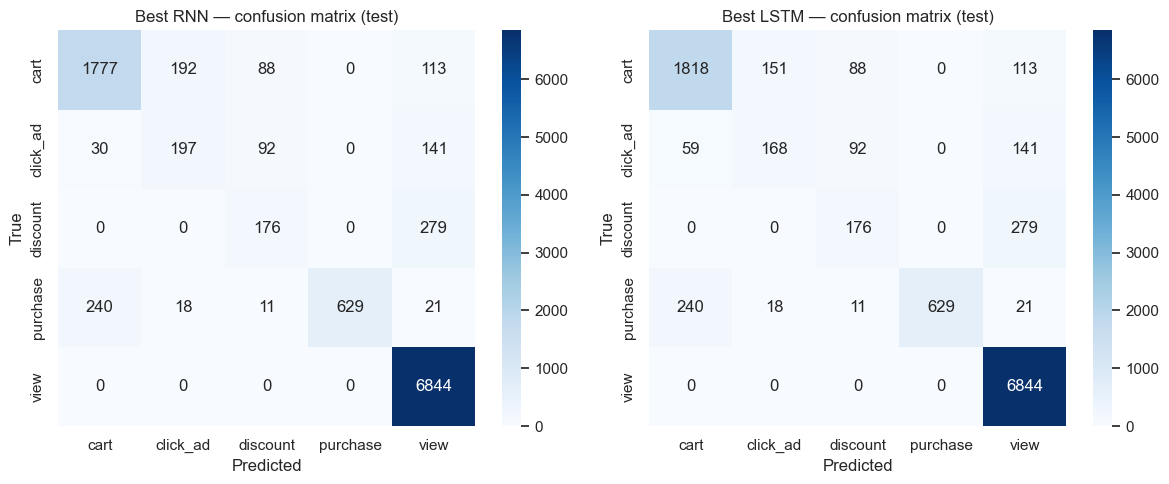

In [42]:
def collect_predictions(model, loader):
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for x, y, _ in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x)
            mask = y != PAD_IDX
            preds.extend(logits.argmax(-1)[mask].cpu().numpy())
            targets.extend(y[mask].cpu().numpy())
    return np.array(targets), np.array(preds)


def print_metrics(name, y_true, y_pred, label_ids, labels):
    acc = accuracy_score(y_true, y_pred)
    f1w = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    f1m = f1_score(y_true, y_pred, average="macro", zero_division=0)
    precw = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    recw = recall_score(y_true, y_pred, average="weighted", zero_division=0)

    print(f"\n{name} — test metrics (padding ignored)")
    print(f"  accuracy:          {acc:.4f}")
    print(f"  precision (wtd):   {precw:.4f}")
    print(f"  recall (wtd):      {recw:.4f}")
    print(f"  F1 (weighted):     {f1w:.4f}")
    print(f"  F1 (macro):        {f1m:.4f}")

    print("\nClassification report:")
    print(
        classification_report(
            y_true,
            y_pred,
            labels=label_ids,
            target_names=labels,
            zero_division=0,
        )
    )


test_loader = DataLoader(
    NextEventDataset(test_df), batch_size=32, shuffle=False, collate_fn=collate_batch
)

y_true, y_pred_rnn = collect_predictions(rnn_model, test_loader)
_, y_pred_lstm = collect_predictions(lstm_model, test_loader)

labels = [id2event[i] for i in range(1, NUM_EVENTS)]
label_ids = list(range(1, NUM_EVENTS))

print_metrics("Best RNN", y_true, y_pred_rnn, label_ids, labels)
print_metrics("Best LSTM", y_true, y_pred_lstm, label_ids, labels)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, pred, title in zip(
    axes,
    [y_pred_rnn, y_pred_lstm],
    ["Best RNN", "Best LSTM"],
):
    cm = confusion_matrix(y_true, pred, labels=label_ids)
    sns.heatmap(cm, annot=True, fmt="d", xticklabels=labels, yticklabels=labels, ax=ax, cmap="Blues")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(f"{title} — confusion matrix (test)")
plt.tight_layout()
plt.show()


## 8. Example next-event predictions

In [43]:
def predict_next_events(model, event_ids):
    """event_ids = input sequence (all but last event); returns predicted next events."""
    model.eval()
    x = torch.tensor([event_ids], dtype=torch.long).to(DEVICE)
    with torch.no_grad():
        logits = model(x)
        pred_ids = logits.argmax(dim=-1).cpu().numpy()[0]
    return [id2event[i] for i in pred_ids]


print("Sample sessions (true next vs RNN vs LSTM):")
for i in range(min(5, len(test_df))):
    events = test_df.iloc[i]["events"]
    ids = encode_events(events)
    inp, true_next = ids[:-1], [id2event[j] for j in ids[1:]]
    rnn_pred = predict_next_events(rnn_model, inp)
    lstm_pred = predict_next_events(lstm_model, inp)
    print(f"\nSession {i}: {' -> '.join(events)}")
    print("  True next:", true_next)
    print("  RNN pred:", rnn_pred)
    print("  LSTM pred:", lstm_pred)

Sample sessions (true next vs RNN vs LSTM):

Session 0: view -> discount -> click_ad -> cart -> cart -> cart -> purchase
  True next: ['discount', 'click_ad', 'cart', 'cart', 'cart', 'purchase']
  RNN pred: ['view', 'click_ad', 'cart', 'cart', 'cart', 'purchase']
  LSTM pred: ['view', 'cart', 'cart', 'cart', 'cart', 'purchase']

Session 1: view -> view -> view -> view -> view -> view -> view -> view -> view -> view -> view -> view -> discount -> click_ad -> cart -> cart -> cart -> purchase
  True next: ['view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'discount', 'click_ad', 'cart', 'cart', 'cart', 'purchase']
  RNN pred: ['view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'discount', 'click_ad', 'cart', 'cart', 'cart', 'purchase']
  LSTM pred: ['view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'discount', 'click_ad', 'cart', 'cart', 'cart', 'purchase']

Session 2: view -> 

## 9. Summary 


- Event sequences are **synthetic** from aggregate session fields.
- Hyperparameter grid: hidden size, layers, dropout, embedding dim, learning rate.
- Best config per architecture chosen by **lowest validation loss** (early stopping).
- Final decision: compare **test accuracy** and **test loss** between best RNN and best LSTM.
- Mention limitations: no real timestamps, funnel assumptions, class imbalance (`purchase` rare in sequences).